# Service provision

`get_service_provision` allocates the demand of buildings to services with limited capacity, given a matrix of
travel costs and a normative threshold. This notebook

1. computes provision with a 10-minute threshold on a precomputed intermodal travel-time matrix;
2. maps the provision value and service load;
3. removes links longer than 15 minutes with `recalculate_links`, and clips the result to a subarea;
4. repeats the calculation with a pandas sparse matrix.

The matrix in `examples_data/matrix_time.parquet` was computed with IduEdu
([calculate_od_matrix](calculate_od_matrix.ipynb)); unreachable pairs are `inf`.

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from objectnat import (
    clip_provision,
    get_provision_buildings,
    get_provision_links,
    get_provision_services,
    get_service_provision,
    recalculate_links,
)

buildings = gpd.read_parquet("examples_data/buildings.parquet")
services = gpd.read_parquet("examples_data/services.parquet")
matrix = pd.read_parquet("examples_data/matrix_time.parquet")  # minutes, rows: buildings, columns: services
print(f"{len(buildings)} buildings (demand {buildings['demand'].sum()}), "
      f"{len(services)} services (capacity {services['capacity'].sum()}), matrix {matrix.shape}")

4101 buildings (demand 29596), 36 services (capacity 31142), matrix (4101, 36)


## 1. Provision within 10 minutes

The result is a `ProvisionResult`: a sparse `flow` matrix of allocated demand and the tables `demand_rows` and
`capacity_rows`. A fixed `seed` makes the allocation reproducible.

In [3]:
result = get_service_provision(buildings=buildings, services=services, distance_matrix=matrix, threshold=10, seed=0)
# the result brings its own demand/capacity columns, so the input ones are dropped before joining
buildings_prov = get_provision_buildings(buildings.drop(columns="demand"), result)
services_prov = get_provision_services(services.drop(columns="capacity"), result)
links = get_provision_links(buildings, services, result)

demand = result.demand_rows
print(f"supplied within 10 min: {demand['supplied_demands_within'].sum() / demand['demand'].sum():.1%}, "
      f"beyond: {demand['supplied_demands_without'].sum() / demand['demand'].sum():.1%}, "
      f"left: {demand['demand_left'].sum() / demand['demand'].sum():.1%}")
result.capacity_rows.describe().round(1)

supplied within 10 min: 61.4%, beyond: 35.2%, left: 3.4%


,capacity,capacity_left,carried_capacity_within,carried_capacity_without,service_load
count,36.0,36.0,36.0,36.0,36.0
mean,865.1,71.2,504.5,289.3,793.8
std,487.1,95.8,318.6,340.5,448.5
min,120.0,0.0,61.0,0.0,95.0
25%,550.8,0.8,241.8,41.0,459.0
50%,960.0,26.0,498.0,186.0,815.5
75%,1200.0,115.5,724.5,454.2,1158.8
max,2161.0,380.0,1150.0,1502.0,1852.0


## 2. Maps

`provision_value` is the share of a building's demand supplied by services within the threshold; `service_load` is
the total demand allocated to a service.

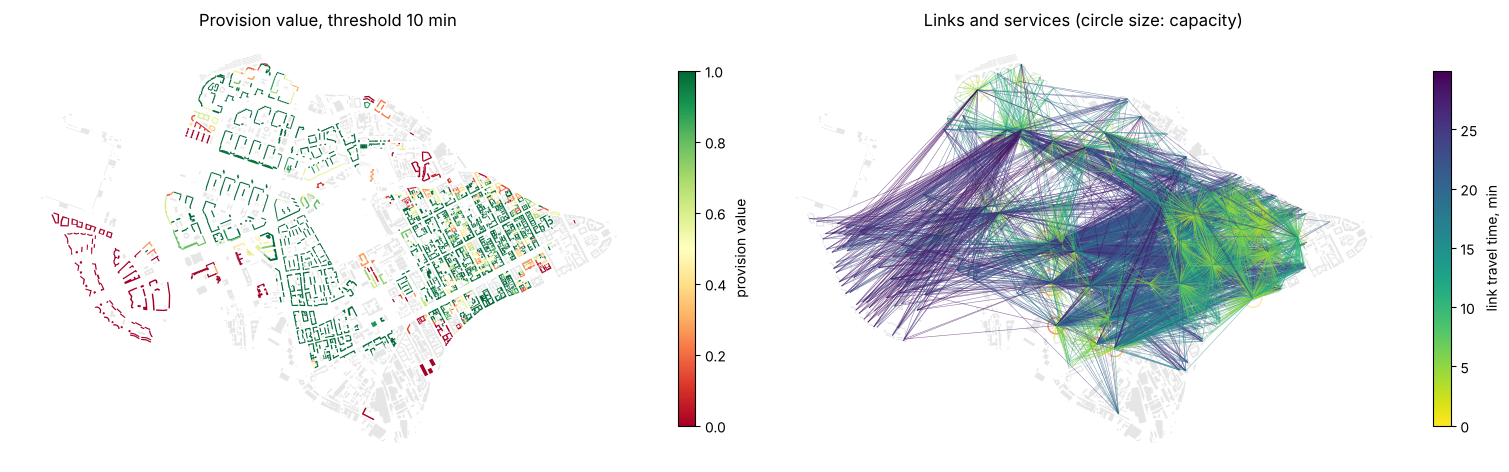

In [4]:
living = buildings_prov[buildings_prov["demand"] > 0]
fig, axs = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
ax = axs[0]
buildings_prov[buildings_prov["demand"] <= 0].plot(ax=ax, color="#e6e6e6", linewidth=0)
living.plot(ax=ax, column="provision_value", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
            legend_kwds={"label": "provision value", "shrink": 0.6})
ax.set_title("Provision value, threshold 10 min")
ax = axs[1]
buildings.plot(ax=ax, color="#e6e6e6", linewidth=0)
links.plot(ax=ax, column="distance", cmap="viridis_r", linewidth=0.4, alpha=0.6, legend=True,
           legend_kwds={"label": "link travel time, min", "shrink": 0.6})
load_share = services_prov["service_load"] / services_prov["capacity"]
services_prov.plot(ax=ax, markersize=10 + 0.15 * services_prov["capacity"], facecolor="none",
                   edgecolor=plt.get_cmap("magma")(np.clip(load_share, 0, 1)), linewidth=1)
ax.set_title("Links and services (circle size: capacity)")
for ax in axs:
    ax.set_axis_off()
plt.show()

## 3. Shorter threshold and clipping

`recalculate_links` removes flows whose cost exceeds `new_max_dist` and rebuilds the metrics; removed demand is not
reallocated. `clip_provision` keeps buildings intersecting a zone, their links and the services they use.

In [5]:
result_8 = recalculate_links(result, new_max_dist=8)
removed = result.demand_rows["demand_left"].sum(), result_8.demand_rows["demand_left"].sum()
print(f"unsupplied demand: {removed[0]} with all links, {removed[1]} after removing links longer than 8 min")

buildings_8 = get_provision_buildings(buildings.drop(columns="demand"), result_8)
services_8 = get_provision_services(services.drop(columns="capacity"), result_8)
links_8 = get_provision_links(buildings, services, result_8)

zone = buildings.iloc[500:503][["geometry"]].copy()
zone["geometry"] = zone.buffer(500)
b_clip, s_clip, l_clip = clip_provision(buildings_8, services_8, links_8, selection_zone=zone)
print(len(b_clip), "buildings,", len(s_clip), "services,", len(l_clip), "links in the zone")

unsupplied demand: 1019 with all links, 13113 after removing links longer than 8 min
449 buildings, 15 services, 363 links in the zone


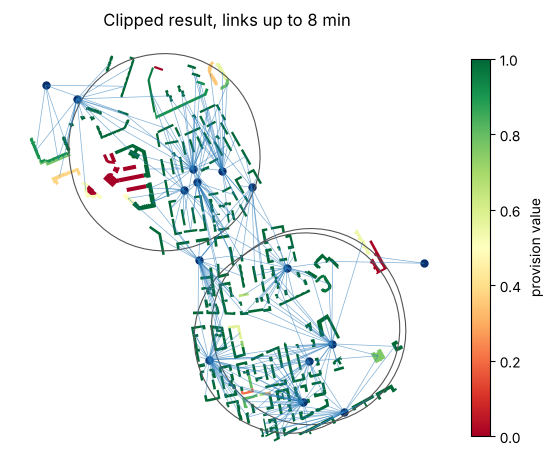

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
zone.boundary.plot(ax=ax, color="#555555", linewidth=0.8)
b_clip[b_clip["demand"] > 0].plot(ax=ax, column="provision_value", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
                                  legend_kwds={"label": "provision value", "shrink": 0.7})
l_clip.plot(ax=ax, color="#2b7bba", linewidth=0.5, alpha=0.6)
s_clip.plot(ax=ax, color="#08306b", markersize=25)
ax.set_title("Clipped result, links up to 8 min")
ax.set_axis_off()
plt.show()

## 4. Sparse matrices

For large areas most building–service pairs are unreachable within any reasonable cost. A pandas sparse DataFrame
with `NaN` (or `inf`) as fill value stores only reachable pairs; `get_service_provision` reads it entry by entry
without densifying. IduEdu's `od_matrix` returns such a matrix.

Only pairs with a cost up to `3 * threshold` take part in the allocation. For a 5-minute threshold the pairs beyond
15 minutes can therefore be dropped without changing the result:

In [7]:
sparse = matrix.where(matrix <= 15).astype(pd.SparseDtype("float64", np.nan))
print(f"dense: {matrix.memory_usage().sum() / 1e6:.2f} MB, sparse (pairs within 15 min): "
      f"{sparse.memory_usage().sum() / 1e6:.2f} MB, density {sparse.sparse.density:.1%}")

dense_5 = get_service_provision(buildings=buildings, services=services, distance_matrix=matrix, threshold=5, seed=0)
sparse_5 = get_service_provision(buildings=buildings, services=services, distance_matrix=sparse, threshold=5, seed=0)
allocation = ["demand_left", "supplied_demands_within", "supplied_demands_without", "avg_dist", "provision_value"]
same = dense_5.demand_rows[allocation].fillna(-1).equals(sparse_5.demand_rows[allocation].fillna(-1))
print("same allocation with the dense and the sparse matrix:", same)
# min_dist is read from the matrix itself: NaN where the nearest service is beyond the 15-minute cut
print("buildings whose nearest service is beyond 15 min:", int(sparse_5.demand_rows["min_dist"].isna().sum()))

dense: 0.59 MB, sparse (pairs within 15 min): 0.31 MB, density 17.6%
same allocation with the dense and the sparse matrix: True
buildings whose nearest service is beyond 15 min: 239
